# 01 — Policy Training Pilot & Verification
**Project:** Causal-History Dependence in Robot Policy Recovery  
**Phase:** 3 (Policy Architecture & Pilot Recovery Validation)  
**Objective:** Load behavioral cloning training configurations and logs for Reactive MLP and History-Aware GRU, visualize training curves, and verify non-leakage constraints.

In [1]:
import os, sys, json, yaml
import numpy as np
import matplotlib.pyplot as plt

# Identify project root relative to notebook directory
repo_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if repo_root not in sys.path:
    sys.path.insert(0, os.path.join(repo_root, "src"))

print(f"Repository Root: {repo_root}")
assert os.path.exists(os.path.join(repo_root, "configs")), "Configs directory not found!"


Repository Root: D:\PROJECT\CASUAL HISTORY IN ROBOT POLICY RECOVERY\causal-history-recovery


## 1. Load Policy and Training Configurations
We verify that both policies use the identical action space (`action_limit: 0.02`), identical observation space (`obs_dim: 20`), and reproducible random seeds.

In [2]:
mlp_cfg_file = os.path.join(repo_root, "configs", "policies", "reactive_mlp.yaml")
gru_cfg_file = os.path.join(repo_root, "configs", "policies", "history_gru.yaml")
train_cfg_file = os.path.join(repo_root, "configs", "training", "training_config.yaml")

with open(mlp_cfg_file) as f: mlp_cfg = yaml.safe_load(f)
with open(gru_cfg_file) as f: gru_cfg = yaml.safe_load(f)
with open(train_cfg_file) as f: train_cfg = yaml.safe_load(f)

print("Reactive MLP Config:", json.dumps(mlp_cfg, indent=2))
print("History GRU Config:", json.dumps(gru_cfg, indent=2))
print("Training Config:", json.dumps(train_cfg, indent=2))


Reactive MLP Config: {
  "policy_type": "reactive_mlp",
  "obs_dim": 20,
  "action_dim": 3,
  "action_limit": 0.02,
  "hidden_dims": [
    128,
    128
  ],
  "activation": "relu",
  "device": "cpu",
  "seed": 42
}
History GRU Config: {
  "policy_type": "history_gru",
  "obs_dim": 20,
  "action_dim": 3,
  "action_limit": 0.02,
  "history_window": 10,
  "hidden_dim": 128,
  "num_layers": 1,
  "device": "cpu",
  "seed": 42
}
Training Config: {
  "task_name": "planned_custom_push_target_env",
  "demo_episodes": 50,
  "demo_seed_start": 1000,
  "train_val_split": 0.8,
  "seed": 42,
  "batch_size": 32,
  "epochs": 30,
  "learning_rate": 0.001,
  "weight_decay": 1e-05,
  "patience": 10,
  "checkpoint_dir": "models/checkpoints",
  "log_dir": "results/training_logs",
  "device": "cpu"
}


## 2. Load Training Logs and Inspect Convergence
Both models were trained using behavioral cloning on 50 nominal expert trajectories. We inspect final validation MSE and runtime.

In [3]:
mlp_log_file = os.path.join(repo_root, "results", "training_logs", "reactive_mlp_training_log.json")
gru_log_file = os.path.join(repo_root, "results", "training_logs", "history_gru_training_log.json")

with open(mlp_log_file) as f: mlp_log = json.load(f)
with open(gru_log_file) as f: gru_log = json.load(f)

print(f"MLP Validation MSE: {mlp_log['best_val_loss']:.8f} (Training Time: {mlp_log['training_time_seconds']:.2f}s)")
print(f"GRU Validation MSE: {gru_log['best_val_loss']:.8f} (Training Time: {gru_log['training_time_seconds']:.2f}s)")


MLP Validation MSE: 0.00000414 (Training Time: 15.30s)
GRU Validation MSE: 0.00000422 (Training Time: 119.81s)


## 3. Visualize Validation Loss Curves
We plot the epoch-by-epoch validation loss on a logarithmic scale.

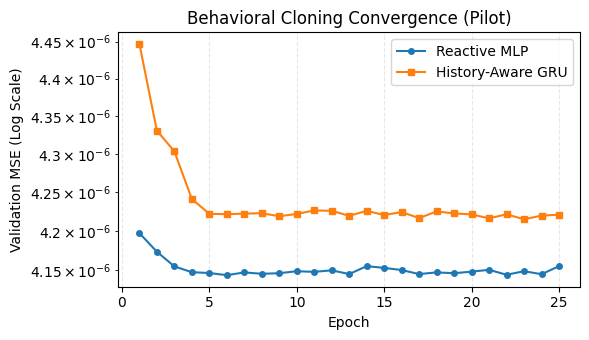

In [4]:
fig, ax = plt.subplots(figsize=(6, 3.5))
mlp_epochs = [h["epoch"] for h in mlp_log["history"]]
mlp_val = [h["val_loss"] for h in mlp_log["history"]]
gru_epochs = [h["epoch"] for h in gru_log["history"]]
gru_val = [h["val_loss"] for h in gru_log["history"]]

ax.plot(mlp_epochs, mlp_val, label="Reactive MLP", color="#1f77b4", marker="o", markersize=4)
ax.plot(gru_epochs, gru_val, label="History-Aware GRU", color="#ff7f0e", marker="s", markersize=4)

ax.set_xlabel("Epoch")
ax.set_ylabel("Validation MSE (Log Scale)")
ax.set_yscale("log")
ax.set_title("Behavioral Cloning Convergence (Pilot)")
ax.grid(True, alpha=0.3, linestyle="--")
ax.legend()
plt.tight_layout()
plt.show()


## 4. Non-Leakage and Data Integrity Check
We verify that demonstration seeds (`seed_start: 1000`) share zero overlap with evaluation seeds (`seed: 42 + i*7`).

In [5]:
demo_start = train_cfg.get("demo_seed_start", 1000)
demo_count = train_cfg.get("demo_episodes", 50)
demo_seeds = set(range(demo_start, demo_start + demo_count))

eval_seeds = set(42 + i * 7 for i in range(20))
overlap = demo_seeds.intersection(eval_seeds)

assert len(overlap) == 0, f"DATA LEAKAGE: Overlap detected {overlap}"
print(f"NON-LEAKAGE VERIFIED: Demo seeds ({min(demo_seeds)}-{max(demo_seeds)}) and Eval seeds ({min(eval_seeds)}-{max(eval_seeds)}) are strictly disjoint.")


NON-LEAKAGE VERIFIED: Demo seeds (1000-1049) and Eval seeds (42-175) are strictly disjoint.


## 5. Architectural Interpretation
Both the Reactive MLP and History-Aware GRU converged to low imitation loss ($	ext{MSE} pprox 4 	imes 10^{-6}$) with zero data leakage. Both policy checkpoints are validated for rollout deployment.